# 03. 고정 모델의 세 목적별 공정조건 탐색

**목표:** 정확한 11개 입력을 확인하고, 같은 후보 예측표에 공동·Ni·Co 목표를 적용합니다. 현재 예측, 추천 상태, 상위 3개, 목표 여유, 시간 반응곡선과 소수 격자 결과를 직접 계산합니다.

본 노트북은 재학습하지 않습니다. 최종 고정 모델 `YP-curve17-dev357-v2`를 사용하며, 예측상 추천은 실제 달성 보장이나 공장 운전 승인이 아닙니다.

In [1]:
from pathlib import Path
import sys
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# 저장소 내부의 어디에서 열어도 루트를 찾습니다. 개인·절대 경로는 사용하지 않습니다.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "module1_preprocessing").is_dir()
             and (p / "module2_prediction").is_dir()
             and (p / "module3_optimization").is_dir()), None)
if ROOT is None:
    raise RuntimeError("저장소 전체를 가져온 뒤 저장소 루트 또는 notebooks 폴더에서 실행하세요.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 24)
pd.set_option("display.precision", 6)
print({"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__})

{'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3'}


## 1. 11개 입력과 현재 공정조건

첫 사례는 `example_no_joint_target.json`의 **합성 혼합 입력 예제**입니다. 실제 한 배치의 관측값이 아니며, 공동 목표를 찾지 못하는 상태를 보여 주기 위한 예제입니다. 4절에서는 관측 개발 배치 `BP-2025-0009`를 별도로 비교합니다.

원료 성분 7개는 wt%, 원료 투입량은 kg, 황산량은 L, 온도는 °C, 시간은 h입니다. 모든 입력은 유한한 숫자이고 성분 합계는 100 wt% 이하여야 합니다. 결측을 자동으로 채우는 추론을 수행하지 않습니다.

In [2]:
from module3_optimization.optimizer import Engine
from module1_preprocessing.schema import BASE, LIMITS, UNITS
from module1_preprocessing.pipeline import load_clean_data

values = json.loads((ROOT / "data" / "examples" / "example_no_joint_target.json").read_text(encoding="utf-8"))
engine = Engine()
assert set(values) == set(BASE)
display(pd.DataFrame([{"input": key, "value": values[key], "unit": UNITS[key],
                       "lower": LIMITS[key][0], "upper": LIMITS[key][1]} for key in BASE]))
current = engine.predict(values)
display(pd.json_normalize(current))

,input,value,unit,lower,upper
0,Ni_함량_pct,22.503,wt%,8.0,30
1,Co_함량_pct,8.352,wt%,2.0,15
2,Li_함량_pct,3.415,wt%,2.0,6
3,Mn_함량_pct,8.368,wt%,5.0,16
4,Cu_불순물_pct,1.144,wt%,0.3,6
5,Fe_불순물_pct,1.393,wt%,0.2,6
6,Al_불순물_pct,2.097,wt%,0.5,7
7,원료투입량_kg,150.000,kg,80.0,200
8,황산투입량_L,900.000,L,400.0,1500
9,침출온도_C,75.000,deg C,40.0,95


,usable,warnings,distance,condition.황산투입량_L,condition.침출온도_C,condition.침출시간_hr,raw_prediction.Ni_pct,raw_prediction.Co_pct,prediction.Ni_pct,prediction.Co_pct
0,True,[],1.403983,900.0,75.0,5.0,89.35915,83.135187,89.35915,83.135187


## 2. 기본 격자와 세 목적

기본 후보 수는 23×12×15 = 4,140개입니다. 원료 성분과 원료 투입량은 고정하고 황산량·온도·시간만 탐색합니다.

| 모드 | 선정 기준 |
|---|---|
| joint | Ni ≥95%, Co ≥90%에서 (100−Ni)²+(100−Co)² 최소 |
| ni | 사용 가능한 후보의 Ni 최대; Co 최소조건 없음 |
| co | 사용 가능한 후보의 Co 최대; Ni 최소조건 없음 |

모든 후보는 물리 출력 0–100%와 거리 지지 검사를 통과해야 합니다. 범위 밖 출력을 잘라 붙이지 않습니다. 거리 통과는 달성 확률이 아닙니다. 세 모드의 조건이 같아도 정상 결과입니다.

In [3]:
FLOORS = {"Ni": 95.0, "Co": 90.0}
result = engine.compare(values, ni_min=FLOORS["Ni"], co_min=FLOORS["Co"], joint_rule="distance")
display(pd.DataFrame([{"candidate_count": result["candidate_count"], "valid_count": result["valid_count"],
                       "output_rejected": result["output_rejected"], "distance_rejected": result["distance_rejected"],
                       "same_candidate_all": result["same_candidate_all"],
                       "plant_operation_approved": result["plant_operation_approved"]}]))

def mode_summary(comparison):
    records = []
    for mode, info in comparison["modes"].items():
        item = info["recommendation"]
        row = {"mode": mode, "status": info["status"], "eligible_count": info["eligible_count"],
               "raw_feasible": info["raw_feasible"], "unsupported_feasible": info["unsupported_feasible"]}
        if item is not None:
            row.update(item["condition"])
            row.update(item["raw_prediction"])
            row["distance"] = item["distance"]
        records.append(row)
    return pd.DataFrame(records)

display(mode_summary(result))
assert result["candidate_count"] == 4140

,candidate_count,valid_count,output_rejected,distance_rejected,same_candidate_all,plant_operation_approved
0,4140,4131,0,9,False,False


,mode,status,eligible_count,raw_feasible,unsupported_feasible,황산투입량_L,침출온도_C,침출시간_hr,Ni_pct,Co_pct,distance
0,joint,TARGET_NOT_FOUND_IN_GRID,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,ni,RECOMMENDED_ON_PREDICTION,4131,4140,9,1500.0,95.0,7.5,95.585636,89.139957,2.212693
2,co,RECOMMENDED_ON_PREDICTION,4131,4140,9,1500.0,95.0,6.5,95.304571,89.296384,2.168484


## 3. 상위 3개와 목표 여유

예제에서 공동 목표를 찾지 못하면 `recommendation`은 비어 있고 참고 대안만 제공됩니다. 참고 대안의 음수 여유는 실제로 그 목표보다 낮다는 뜻입니다. 순수 Ni·Co 목적의 최소조건은 바뀌지 않습니다. 아래 표에서 이 두 목적에 대해 계산한 문턱과의 차이는 참고값입니다.

In [4]:
def candidate_rows(comparison, context):
    rows = []
    for mode, info in comparison["modes"].items():
        items = [(f"rank {rank}", item) for rank, item in enumerate(info["top_candidates"], start=1)]
        if info["closest_alternative"] is not None:
            items.append(("reference alternative; target not met", info["closest_alternative"]))
        for kind, item in items:
            pred = item["raw_prediction"]
            rows.append({"context": context, "mode": mode, "kind": kind,
                         **item["condition"], **pred, "distance": item["distance"],
                         "Ni_minus_95_pp_reference": pred["Ni_pct"] - FLOORS["Ni"],
                         "Co_minus_90_pp_reference": pred["Co_pct"] - FLOORS["Co"],
                         "usable": item["usable"]})
    return pd.DataFrame(rows)

display(candidate_rows(result, "provided example"))
if result["modes"]["joint"]["closest_alternative"] is not None:
    display(pd.json_normalize(result["modes"]["joint"]["closest_alternative"]))

,context,mode,kind,황산투입량_L,침출온도_C,침출시간_hr,Ni_pct,Co_pct,distance,Ni_minus_95_pp_reference,Co_minus_90_pp_reference,usable
0,provided example,joint,reference alternative; target not met,1500.0,95.0,6.5,95.304571,89.296384,2.168484,0.304571,-0.703616,True
1,provided example,ni,rank 1,1500.0,95.0,7.5,95.585636,89.139957,2.212693,0.585636,-0.860043,True
2,provided example,ni,rank 2,1500.0,95.0,8.0,95.569324,88.881734,2.279169,0.569324,-1.118266,True
3,provided example,ni,rank 3,1500.0,95.0,7.0,95.497385,89.278173,2.175296,0.497385,-0.721827,True
4,provided example,co,rank 1,1500.0,95.0,6.5,95.304571,89.296384,2.168484,0.304571,-0.703616,True
5,provided example,co,rank 2,1500.0,95.0,7.0,95.497385,89.278173,2.175296,0.497385,-0.721827,True
6,provided example,co,rank 3,1450.0,95.0,6.5,95.180769,89.234996,2.152265,0.180769,-0.765004,True


,usable,warnings,distance,candidate_id,condition.황산투입량_L,condition.침출온도_C,condition.침출시간_hr,raw_prediction.Ni_pct,raw_prediction.Co_pct,prediction.Ni_pct,prediction.Co_pct,margin_pp.Ni,margin_pp.Co
0,True,[],2.168484,4136,1500.0,95.0,6.5,95.304571,89.296384,95.304571,89.296384,0.304571,-0.703616


## 4. 실제 개발 배치의 다른 원료 예제

`BP-2025-0009`는 완전 관측 개발 배치입니다. 그 11개 입력을 읽어 같은 엔진으로 계산합니다. 특정 원료 예제의 성공·실패는 전체 추천 성능을 대표하지 않습니다.

In [5]:
development = load_clean_data().iloc[:357]
observed_row = development.loc[development["배치ID"].eq("BP-2025-0009")].iloc[0]
assert observed_row[list(BASE)].notna().all()
observed_values = {key: float(observed_row[key]) for key in BASE}
display(pd.DataFrame([observed_values]))
observed_result = engine.compare(observed_values)
display(mode_summary(observed_result))
display(candidate_rows(observed_result, "BP-2025-0009"))

,Ni_함량_pct,Co_함량_pct,Li_함량_pct,Mn_함량_pct,Cu_불순물_pct,Fe_불순물_pct,Al_불순물_pct,원료투입량_kg,황산투입량_L,침출온도_C,침출시간_hr
0,24.78,9.75,3.55,5.89,0.46,0.49,1.08,178.6,712.0,81.6,6.1


,mode,status,eligible_count,raw_feasible,unsupported_feasible,황산투입량_L,침출온도_C,침출시간_hr,Ni_pct,Co_pct,distance
0,joint,RECOMMENDED_ON_PREDICTION,81,81,0,1500.0,95.0,7.0,96.351634,91.507362,2.085485
1,ni,RECOMMENDED_ON_PREDICTION,4089,4140,51,1500.0,95.0,7.5,96.439885,91.369145,2.134569
2,co,RECOMMENDED_ON_PREDICTION,4089,4140,51,1500.0,95.0,6.5,96.158820,91.525573,2.067998


,context,mode,kind,황산투입량_L,침출온도_C,침출시간_hr,Ni_pct,Co_pct,distance,Ni_minus_95_pp_reference,Co_minus_90_pp_reference,usable
0,BP-2025-0009,joint,rank 1,1500.0,95.0,7.0,96.351634,91.507362,2.085485,1.351634,1.507362,True
1,BP-2025-0009,joint,rank 2,1500.0,95.0,6.5,96.158820,91.525573,2.067998,1.158820,1.525573,True
2,BP-2025-0009,joint,rank 3,1500.0,95.0,7.5,96.439885,91.369145,2.134569,1.439885,1.369145,True
3,BP-2025-0009,ni,rank 1,1500.0,95.0,7.5,96.439885,91.369145,2.134569,1.439885,1.369145,True
4,BP-2025-0009,ni,rank 2,1500.0,95.0,8.0,96.423573,91.110923,2.213150,1.423573,1.110923,True
5,BP-2025-0009,ni,rank 3,1500.0,95.0,7.0,96.351634,91.507362,2.085485,1.351634,1.507362,True
6,BP-2025-0009,co,rank 1,1500.0,95.0,6.5,96.158820,91.525573,2.067998,1.158820,1.525573,True
7,BP-2025-0009,co,rank 2,1500.0,95.0,7.0,96.351634,91.507362,2.085485,1.351634,1.507362,True
8,BP-2025-0009,co,rank 3,1450.0,95.0,6.5,96.035018,91.464185,1.993362,1.035018,1.464185,True


## 5. 시간 반응곡선: 같은 모델의 연속 수치 계산

황산 1500 L·온도 95 °C에서 시간만 바꾸어 원시 예측을 그립니다. 제곱항 때문에 Ni·Co의 최대 위치가 다를 수 있습니다. 지원 여부도 별도로 계산합니다. 원료-공정 상호작용이 없는 모델이므로 이 곡선을 원료별 반응 메커니즘의 실측 검증으로 읽지 않습니다.

,time_hr,Ni_pct,Co_pct,distance,physical,supported,usable
0,1.0,86.282459,81.576322,2.267502,True,True,True
20,2.0,88.863910,84.060022,2.234037,True,True,True
40,3.0,91.027109,86.063698,2.319116,True,True,True
60,4.0,92.772056,87.587351,2.411364,True,True,True
80,5.0,94.098751,88.630982,2.296029,True,True,True
100,6.0,95.007194,89.194589,2.184350,True,True,True
120,7.0,95.497385,89.278173,2.175296,True,True,True
140,8.0,95.569324,88.881734,2.279169,True,True,True


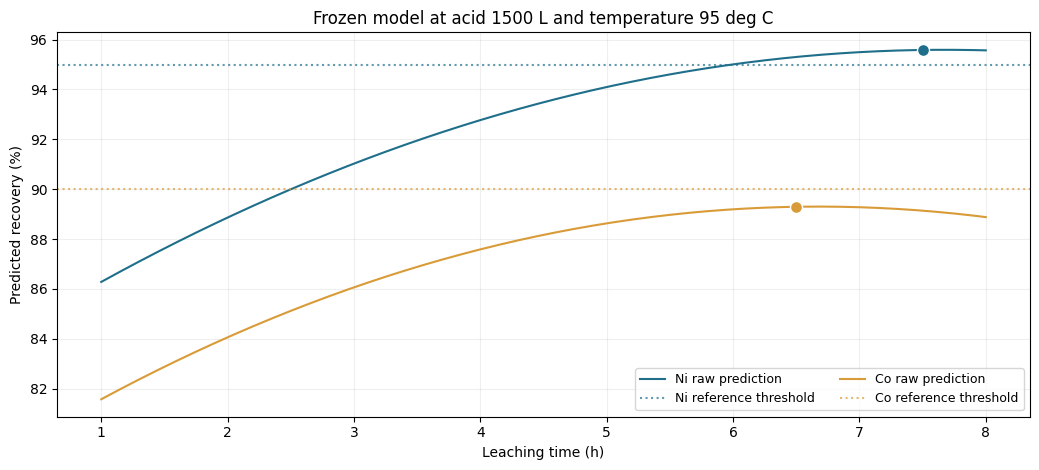

,time_hr,Ni_pct,Co_pct,distance,physical,supported,usable
133,7.65,95.591722,89.075091,2.229679,True,True,True
134,7.70,95.591659,89.051068,2.235914,True,True,True
132,7.60,95.590739,89.097913,2.223729,True,True,True


,time_hr,Ni_pct,Co_pct,distance,physical,supported,usable
113,6.65,95.373394,89.303521,2.167274,True,True,True
114,6.70,95.394244,89.303500,2.167491,True,True,True
112,6.60,95.351499,89.302342,2.167367,True,True,True


In [6]:
times = np.linspace(1.0, 8.0, 141)
x = np.tile(np.array([values[key] for key in BASE], dtype=float), (len(times), 1))
x[:, 8], x[:, 9], x[:, 10] = 1500.0, 95.0, times
predictions, distances = engine.calculate(x)
physical = np.isfinite(predictions).all(axis=1) & (predictions >= 0).all(axis=1) & (predictions <= 100).all(axis=1)
supported = distances <= engine.threshold
curve = pd.DataFrame({"time_hr": times, "Ni_pct": predictions[:, 0], "Co_pct": predictions[:, 1],
                      "distance": distances, "physical": physical, "supported": supported,
                      "usable": physical & supported})
display(curve.iloc[::20])
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for metal, color in (("Ni", "#1F6F8B"), ("Co", "#D99B37")):
    ax.plot(curve["time_hr"], curve[f"{metal}_pct"], color=color, label=f"{metal} raw prediction")
    ax.axhline(FLOORS[metal], color=color, ls=":", alpha=.7, label=f"{metal} reference threshold")
    selected = result["modes"][metal.lower()]["recommendation"]
    if selected is not None:
        ax.scatter(selected["condition"]["침출시간_hr"], selected["raw_prediction"][f"{metal}_pct"],
                   color=color, s=75, zorder=5, edgecolor="white")
ax.set(xlabel="Leaching time (h)", ylabel="Predicted recovery (%)",
       title="Frozen model at acid 1500 L and temperature 95 deg C")
ax.grid(alpha=.2)
ax.legend(loc="best", ncol=2, fontsize=9)
fig.tight_layout()
display(fig)
plt.close(fig)
display(curve.loc[curve["usable"]].nlargest(3, "Ni_pct"))
display(curve.loc[curve["usable"]].nlargest(3, "Co_pct"))

## 6. 소수 격자 비교와 탐색 비용

25 L·2.5 °C·0.25 h 격자는 30,015개로 기본 4,140개보다 촘촘합니다. 한 번의 탐색은 50,000개 이하로 제한합니다. 격자를 세분화하면 같은 예측함수의 수치적 최대점에 더 가까워질 수 있지만, 새 실측이 생기거나 예측 정확도가 개선되지는 않습니다.

In [7]:
finer_grid = {"황산투입량_L": np.linspace(400, 1500, 45).tolist(),
              "침출온도_C": np.linspace(40, 95, 23).tolist(),
              "침출시간_hr": np.linspace(1, 8, 29).tolist()}
finer = engine.compare(observed_values, grid=finer_grid)
coarse_table = mode_summary(observed_result).assign(grid="default", candidate_count=observed_result["candidate_count"])
finer_table = mode_summary(finer).assign(grid="25 L / 2.5 C / 0.25 h", candidate_count=finer["candidate_count"])
display(pd.concat([coarse_table, finer_table], ignore_index=True))
gain_rows = []
for mode, metal in (("ni", "Ni_pct"), ("co", "Co_pct")):
    coarse_choice = observed_result["modes"][mode]["recommendation"]
    fine_choice = finer["modes"][mode]["recommendation"]
    if coarse_choice is not None and fine_choice is not None:
        gain_rows.append({"mode": mode, "predicted_objective_gain_pp":
                          fine_choice["raw_prediction"][metal] - coarse_choice["raw_prediction"][metal]})
display(pd.DataFrame(gain_rows))
assert finer["candidate_count"] == 30015

,mode,status,eligible_count,raw_feasible,unsupported_feasible,황산투입량_L,침출온도_C,침출시간_hr,Ni_pct,Co_pct,distance,grid,candidate_count
0,joint,RECOMMENDED_ON_PREDICTION,81,81,0,1500.0,95.0,7.00,96.351634,91.507362,2.085485,default,4140
1,ni,RECOMMENDED_ON_PREDICTION,4089,4140,51,1500.0,95.0,7.50,96.439885,91.369145,2.134569,default,4140
2,co,RECOMMENDED_ON_PREDICTION,4089,4140,51,1500.0,95.0,6.50,96.158820,91.525573,2.067998,default,4140
3,joint,RECOMMENDED_ON_PREDICTION,509,509,0,1500.0,95.0,7.00,96.351634,91.507362,2.085485,25 L / 2.5 C / 0.25 h,30015
4,ni,RECOMMENDED_ON_PREDICTION,29775,30015,240,1500.0,95.0,7.75,96.444799,91.255035,2.170345,25 L / 2.5 C / 0.25 h,30015
5,co,RECOMMENDED_ON_PREDICTION,29775,30015,240,1500.0,95.0,6.75,96.268298,91.531468,2.072708,25 L / 2.5 C / 0.25 h,30015


,mode,predicted_objective_gain_pp
0,ni,0.004914
1,co,0.005895


## 7. 공동 기준을 바꾸어 보기

`maximin`은 두 목표 최소값을 충족한 후보에서 더 낮은 회수율을 최대화합니다. `distance`와 공통 예측·필터를 사용하며, 목적 기준만 달라집니다. 두 기준의 선택이 같아도 문제가 아닙니다.

In [8]:
maximin_result = engine.compare(observed_values, joint_rule="maximin")
comparison = pd.concat([mode_summary(observed_result).query("mode == 'joint'").assign(joint_rule="distance"),
                        mode_summary(maximin_result).query("mode == 'joint'").assign(joint_rule="maximin")], ignore_index=True)
display(comparison)

,mode,status,eligible_count,raw_feasible,unsupported_feasible,황산투입량_L,침출온도_C,침출시간_hr,Ni_pct,Co_pct,distance,joint_rule
0,joint,RECOMMENDED_ON_PREDICTION,81,81,0,1500.0,95.0,7.0,96.351634,91.507362,2.085485,distance
1,joint,RECOMMENDED_ON_PREDICTION,81,81,0,1500.0,95.0,6.5,96.158820,91.525573,2.067998,maximin


## 결과 해석

| 상태 | 의미 |
|---|---|
| RECOMMENDED_ON_PREDICTION | 해당 목적의 사용 가능한 예측 후보 있음 |
| TARGET_NOT_FOUND_IN_GRID | 사용 가능한 후보는 있으나 공동 목표 미발견 |
| TARGET_FOUND_BUT_UNSUPPORTED | 목표 충족 예측 후보가 거리 검사에서 제외됨 |
| NO_SUPPORTED_CANDIDATE | 물리 유효 후보 중 거리 통과 후보 없음 |
| NO_VALID_MODEL_OUTPUT | 0–100%의 유한한 모델 출력 후보 없음 |

상위 3개는 이 모델·격자의 순위이고 실제 우월성을 입증하지 않습니다. 현재 결과의 기대 효과는 실험 후보와 검토 사유를 정리하는 데 있습니다. 실제 공정 적용에는 새 실측 검증이 필요합니다.

목적별 선정 기준과 상태값은 모듈 설명에 있습니다. 예제 결과에는 추천 후보와 공동 목표를 달성하지 못한 경우가 담겨 있습니다. [최적화 모듈 설명](../module3_optimization/README.md) · [추천 결과](../module3_optimization/results/recommendations.json) · [공동 목표 미발견 결과](../module3_optimization/results/no_joint_target.json)